# Figure 6: Change-Point Summary

Translation of `Figure06_cpSummary.m`

## What this notebook does

Characterizes how participants adjust their decision bounds in response to a **change point (CP)**
in the generative process. In CP trials the SNR shifts mid-block at a random time; the optimal
response is to increase or decrease the bound to maximize reward rate (RR) at the new SNR.

All statistics are computed once, early in the notebook, and plotted only once — in the
**Formatted figure** section near the end. There are no separate "preview" plots above; the
computation cells below print their results as text so you can sanity-check numbers before the
combined figure is built.

**3-row, 2-column figure layout** (columns = LowHigh / HighLow CP directions). Each row uses its
own, deliberately distinct visual encoding, since the three rows show unrelated quantities:

- **Row 1 — Example RR curve**: One example subject's smoothed RR vs. bound curve at their
  actual CP step, with markers at the pre-CP bound (open circle), optimal bound (blue ★), and
  post-CP bound (filled black circle).
- **Row 2 — Bound change vs. RR gradient**: one panel per condition. The x-axis is `gradient`
  — the RR secant slope from the pre-CP bound to the RR-optimal bound, signed automatically
  (positive when the RR-optimal bound is above the pre-CP bound, negative when it's below).
  Point fill color encodes the subject's raw pre-CP bound on a dedicated blue-red gradient
  (shared scale across both panels, distinct from Row 3 panel F's viridis RR heatmap). Each panel
  is annotated with the pooled Spearman correlation (gradient vs. bound change) and a Wilcoxon
  signed-rank test of whether the bound change differs from zero (panel D's test uses an
  RR-gradient-adjusted bound change; see "Statistical tests" below).
- **Row 3 — Post-CP bound comparison**: Left (panel E): LowHigh post-CP bound vs. HighLow
  post-CP bound (Wilcoxon signed-rank p-value), with per-subject SEM errorbars in both
  directions. Right (panel F): Low bound vs. High bound in the corresponding stable-SNR (no-CP)
  conditions, with per-subject SEM errorbars and the expected reward-rate landscape drawn as a
  background heatmap spanning the full panel (near-optimal region outlined in blue, peak marked
  with a blue star), matching the manuscript's Fig. 6F and the heatmap styling used in
  `Figure05_mixedVsBlockedSNR.ipynb`.

## Statistical tests

Computed once, right after the RR benchmark, and used both as Row 2 panel annotations and
throughout "Key findings" below:

1. **Spearman correlation, bound change vs. RR gradient** (`spearman_pooled`) — one pooled
   correlation per condition.
2. **Wilcoxon signed-rank test, bound change vs. zero** (`wilcoxon_median`) — LowHigh uses the
   raw bound change; HighLow uses an RR-gradient-adjusted bound change (raw Δ × sign(gradient),
   i.e. Δ flipped for subjects whose RR-optimal bound is below their pre-CP bound), since HighLow
   has a substantial number of subjects on each side of gradient = 0 and pooling raw, unadjusted
   deltas would let opposite-direction subjects' changes cancel even if both groups reliably move
   toward their own RR optimum.
3. **Spearman correlation, bound change vs. raw pre-CP bound** (`spearman_prebound`) — an
   independent question, since pre-CP bound is not the same quantity as gradient.

## Data requirements

Per-subject CP bound summaries are computed directly from raw data at the top of this notebook
(`get_data_table(task_type='MXSC')` + `pigeon.data.get_bound_summaries_wcp`) --
fields: `LowHigh` (n_subjects × 2: [pre-CP bound, post-CP bound] for Low→High transitions),
`HighLow`, `Low`, `High`, `CPLowHigh` (CP step per subject), `CPHighLow`, and `SEM*` counterparts
of each bound field (used for the Row 3 errorbars).

The reward-rate matrices are the one piece still loaded from a pre-computed file, since they take
hours to simulate:

**`RRMats.mat`**: Reward-rate matrices from `Make_RRMatrix.ipynb` with `COMPUTE_CP = True`.
Fields: `pmats` (1×2 cell array — `pmats{1}` = LowHigh matrix, `pmats{2}` = HighLow matrix,
each `n_bounds × n_bounds × n_cp_steps`), `bounds`, `cp_steps_lh`, `cp_steps_hl`, `g_means`,
`g_std`. Must be built with `G_MEANS = [0.01, 0.02]` and `G_STD = 0.05` to match the actual
pigeon task parameters.

Panel F's reward-rate landscape is *not* loaded from a file — it's computed inline via
`pigeon.simulation.get_simulated_data_table` (specs mode) on a dedicated, wider bound grid
(`STABLE_BOUNDS`) than the CP-task `BOUNDS`, since it only needs cohort 3's known generative
parameters and its panel spans a wider bound range than the CP RR matrices cover.


## Key findings

*(Read this first — the analysis and figure below support these results.)*

**Note:** these numbers reflect a 2026-08 fix to how each subject's CP step is computed. Some
subjects' change-point step was previously recomputed post-hoc as `round(mean(RT))` of their
fixed low-/high-SNR block, uniformly for everyone — but not every subject's task-code version
actually used that formula online: some used an unrounded `median(RT)` instead (see
`pigeon.data.get_data_table`'s `is_sc` branch and `data/mxsc_cp_method.txt`). A few of those
subjects' switch step landed on a half-integer (even-trial-count fixed block) and can never match
the online switch trigger's exact-integer comparison, so their SNR change never actually fired --
those subjects are excluded (see "Data exclusion summary" above). This is also the point where the
earlier per-direction split used in earlier versions of this notebook (grouping subjects by
whether the RR-optimal bound was above or below their pre-CP bound, and reporting a separate
correlation for each group) was removed in favor of pooled statistics (with an RR-gradient sign
adjustment for HighLow's Wilcoxon test; see "Statistical tests" above).

### Bound change vs. RR gradient (Row 2 / panels C, D)

- **LowHigh**: gradient vs. Δ, ρ=+0.304, p=0.0375 (n=47); Δ vs. 0 (Wilcoxon), median=+0.014,
  p=0.037 (31 up / 16 down) — subjects on average raise their bound after the change point, and
  do so more the larger the RR gradient favors raising.
- **HighLow**: gradient vs. Δ, ρ=+0.546, p<0.0001 (n=51); RR-gradient-adjusted Δ vs. 0
  (Wilcoxon), median=+0.017, p=0.0069 (33 up / 18 down) — subjects move their bound in the
  RR-recommended direction (whether that's up or down) more than expected by chance, and do so
  more the larger the RR gradient.

**Comparison to the manuscript:** Fig. 6C/D report ρ=0.34 (p=0.011, LowHigh) and ρ=0.26
(p=0.048, HighLow) for the pooled gradient correlation. LowHigh (+0.304) is close. HighLow
(+0.546) is now noticeably higher than the manuscript value — a direct consequence of correcting
each subject's CP step to match the formula their task-code version actually used online, not a
new discrepancy to explain away.

### Pre-CP bound vs. bound change (independent test, not split)

Both conditions show a significant *negative* relationship between a subject's raw pre-CP bound
and their bound change — **LowHigh**: ρ=−0.350, p=0.0111 (n=52); **HighLow**: ρ=−0.556, p<0.0001
(n=55). Higher pre-CP bound predicts a smaller (or more negative) bound change in both conditions,
on top of (or instead of) whatever the RR gradient captures — subjects who started with an
already-high bound tend to raise it less or cut it more, a pattern consistent with reversion
toward a preferred bound level as much as with RR-optimal tracking.

**Caveat:** this is a model-based account — it explains what the RR matrix says is optimal given
each subject's actual pre-CP bound and CP step, not direct evidence of what participants compute.

### Post-CP and stable-SNR bound comparisons (Row 3 / panels E, F)

- **Panel E**: LowHigh post-CP bound is significantly higher than HighLow post-CP bound
  (Wilcoxon p<0.0001, n=51) — consistent with the two post-CP conditions ending at genuinely
  different SNR levels (high vs. low) rather than converging to one preferred bound.
- **Panel F**: no significant difference between the stable (no-CP) Low and High bounds
  (Wilcoxon p=0.308, n=59). Neither sits at the RR-maximizing peak, though: only 2/59 subjects'
  (lo, hi) bound pairs fall in the near-optimal (≥95% of max RR) region: the median subject's
  bounds achieve ~79% of the maximum attainable RR, well above chance but short of optimal.


In [1]:
import sys
sys.path.insert(0, '..')

import os
import numpy as np
import scipy.io
import scipy.stats
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.colors as mcolors

from pigeon.data import get_data_table
from pigeon.data import get_bound_summaries_wcp
from pigeon.pathDefaults import BIAS_CORRECTION_CP_FILE, RR_MATS_FILE, FIGURES_DIR
from pigeon.plotting import FONT_RC, add_panel_label
from pigeon.simulation import get_simulated_data_table

# BOUNDS is loaded from RR_MATS_FILE below (cell that loads pmats) -- it is the
# actual, possibly non-uniform CP-scale grid Make_RRMatrix.ipynb built the RR
# matrices with, not a hardcoded MX-style uniform grid.

# Condition labels and example subject indices (MATLAB 1-indexed: tt=1→pp=53, tt=2→pp=52)
TITLES           = ['LowHigh', 'HighLow']
EXAMPLE_SUBJECTS = {0: 52, 1: 51}   # 0-indexed -- chosen against an older subject
# ordering; may not point at a representative-looking example subject now that
# get_data_table reads Pigeon_MXSC's current 60-subject cohort. Revisit if Row 1's
# example panel looks off.

# Row 2's pre-CP-bound color scale: a dedicated blue-red gradient, distinct from
# Row 3 panel F's viridis RR heatmap, since the two rows encode unrelated quantities
# (a per-subject bound value vs. a simulated reward rate).
PRE_BOUND_CMAP = mcolors.LinearSegmentedColormap.from_list('blue_red', ['tab:blue', 'tab:red'])

## Load data

Bound summaries are computed directly from the raw CP data (`get_data_table` +
`get_bound_summaries_wcp`) -- fast enough (seconds) that caching them via a
separate notebook + `.mat` file bought nothing but a staleness risk (see git
history: this used to load a pre-computed `NEW_boundSummaries_wCP.mat` from
`Make_cpBoundSummaries.ipynb`, which silently went stale multiple times across
data-source and bias-correction fixes). Only the RR matrices are still loaded
from a pre-computed file, since `Make_RRMatrix.ipynb` takes hours to run --
raises `FileNotFoundError` with a clear message if it's missing.

**Data included**: All subjects from the CP task; all unique CP times.

**Data excluded**: Subjects with non-finite pre- or post-CP bounds (`isfinite` filter applied
during plotting). Also, per-block, subjects whose CP step (`change_point`) is `NaN` --
`get_data_table` sets this for 'median'-formula subjects (see `pigeon.data.get_data_table`'s
`is_sc` branch) whose fixed low-/high-SNR block had an even trial count: their in-task
`calculate_median()`-derived switch step was a half-integer, which the online switch trigger
(`steps_in_trial === switch_time`, an exact match against an integer) could never satisfy, so
the SNR change never actually fired for that block. Rather than assign a switch step that was
never really reached, `get_data_table` leaves `change_point` as `NaN`, which makes the whole
block collapse into the pre-change bucket (no post-change bound), and such subjects are then
dropped here by the `isfinite` filter. See the **Data exclusion summary** section below (after the
RR-benchmark cell) for the full per-condition tally, including the further exclusions specific to
the RR-gradient stats (panels C/D).

In [2]:
data_table_mxsc = get_data_table(
    task_type='MXSC',
    combine_snr=False, correct_bias=BIAS_CORRECTION_CP_FILE,
)
bound_summaries = get_bound_summaries_wcp(data_table_mxsc)

lh_bounds = np.asarray(bound_summaries['LowHigh'])    # (n_subjects, 2): col 0 = pre-CP, col 1 = post-CP
hl_bounds = np.asarray(bound_summaries['HighLow'])
lo_bounds = np.asarray(bound_summaries['Low'])        # stable Low blocks: (n_subjects, 2)
hi_bounds = np.asarray(bound_summaries['High'])       # stable High blocks
cp_lh     = np.asarray(bound_summaries['CPLowHigh'])  # (n_subjects,): CP step for LowHigh trials
cp_hl     = np.asarray(bound_summaries['CPHighLow'])

# Per-subject SEM, same shape/column convention as the bound arrays above --
# used for the Row 3 (panels E, F) errorbars.
sem_lh = np.asarray(bound_summaries['SEMLowHigh'])
sem_hl = np.asarray(bound_summaries['SEMHighLow'])
sem_lo = np.asarray(bound_summaries['SEMLow'])
sem_hi = np.asarray(bound_summaries['SEMHigh'])

if not os.path.exists(RR_MATS_FILE):
    raise FileNotFoundError(
        f'{RR_MATS_FILE!r} not found.\n'
        'This file is generated by Make_RRMatrix.ipynb with COMPUTE_CP = True.'
    )

# Load RR matrices: pmats is a 2-element cell → Python list of arrays
# pmats[0] = LowHigh RR matrix (n_bounds × n_bounds × n_lh_cp_steps)
# pmats[1] = HighLow RR matrix (n_bounds × n_bounds × n_hl_cp_steps)
# Separate cp_steps arrays because LowHigh and HighLow have different unique CP steps.
rr_mat = scipy.io.loadmat(RR_MATS_FILE, squeeze_me=True, struct_as_record=False)

# The bound grid the RR matrix was actually built with (Make_RRMatrix.ipynb's
# CP_BOUNDS) -- loaded from the file, not hardcoded, since it is CP-scale
# specific and non-uniformly spaced (see Make_RRMatrix.ipynb).
BOUNDS = np.atleast_1d(rr_mat['bounds']).astype(float)
pmats  = list(rr_mat['pmats'].flat)

if 'cp_steps_lh' not in rr_mat or 'cp_steps_hl' not in rr_mat:
    raise KeyError(
        "RRMats.mat uses the old format (single 'cp_steps' field).\n"
        "Regenerate by running Make_RRMatrix.ipynb with COMPUTE_CP = True.\n"
        "The new format stores separate 'cp_steps_lh' and 'cp_steps_hl' fields "
        "so that each condition's matrix uses the actual unique CP steps from the data."
    )

cp_steps_lh      = rr_mat['cp_steps_lh']    # CP steps for LowHigh matrix (3rd axis)
cp_steps_hl      = rr_mat['cp_steps_hl']    # CP steps for HighLow matrix (3rd axis)
cp_steps_by_cond = [cp_steps_lh, cp_steps_hl]

# nanpercentile, not percentile: cp_lh/cp_hl carry NaN for 'median'-formula
# subjects whose fixed block had an even trial count -- calculate_median() in
# task/MXSC/PigeonTask.js returns a half-integer switch_time there, and the
# online switch trigger (steps_in_trial === switch_time) can never match a
# half-integer, so the SNR change never actually fired for that block. Those
# subjects are excluded (NaN) rather than assigned a switch step that was
# never really reached -- see pigeon.data.get_data_table's is_sc branch.
print(f'LowHigh:  median [IQR] CP step = '
      f'{np.nanpercentile(cp_lh, 50):.1f} [{np.nanpercentile(cp_lh, 25):.1f} '
      f'{np.nanpercentile(cp_lh, 75):.1f}]  ({np.sum(np.isnan(cp_lh))} subjects excluded, no-fire switch)')
print(f'HighLow:  median [IQR] CP step = '
      f'{np.nanpercentile(cp_hl, 50):.1f} [{np.nanpercentile(cp_hl, 25):.1f} '
      f'{np.nanpercentile(cp_hl, 75):.1f}]  ({np.sum(np.isnan(cp_hl))} subjects excluded, no-fire switch)')
print(f'Matrix LowHigh CP steps ({len(cp_steps_lh)}): {cp_steps_lh[0]}–{cp_steps_lh[-1]}')
print(f'Matrix HighLow CP steps ({len(cp_steps_hl)}): {cp_steps_hl[0]}–{cp_steps_hl[-1]}')

LowHigh:  median [IQR] CP step = 9.0 [7.0 14.0]  (3 subjects excluded, no-fire switch)
HighLow:  median [IQR] CP step = 8.0 [6.0 10.0]  (3 subjects excluded, no-fire switch)
Matrix LowHigh CP steps (21): 3–37
Matrix HighLow CP steps (15): 3–48


/Users/jigold/miniconda3/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/notebooks/../pigeon/data.py:1220: RuntimeWarning: Mean of empty slice
  acc_summary[ii, 1] = np.nanmean(cond_table.loc[ls, "correct"]) if ls.any() else np.nan


## Rows 1–2: Example RR curve and bound change vs. gradient

Computed here; plotted together with Row 3 in the single **Formatted figure** section near the
end of this notebook (no separate preview plots).

**Row 1** shows one example subject's smoothed RR vs. bound curve at their actual CP step, with
markers at the pre-CP bound (open circle), optimal post-CP bound (blue ★), and actual post-CP
bound (filled black circle).

**Row 2** shows each subject's bound change (post − pre CP) against the RR gradient (secant slope
from the pre-CP bound to the RR-optimal bound). gradient is signed automatically (positive when
the RR-optimal bound is above the pre-CP bound, negative when it's below, since RR_opt ≥ RR_pre
always). Each panel is annotated with the pooled Spearman correlation (gradient vs. Δ) and a
Wilcoxon test of whether the bound change differs from zero (see the stats cell below for why
panel D's test uses an RR-gradient-adjusted Δ). Point fill color encodes the subject's raw pre-CP
bound on a dedicated blue-red gradient (shared scale across both panels, kept visually distinct
from Row 3 panel F's viridis RR heatmap); all points share a single edge color. Both condition
panels share the same x-axis range (−100 to 200) so gradient magnitudes are directly comparable
between LowHigh and HighLow.


In [3]:
# ── Compute per-subject RR benchmark ──────────────────────────────────────────
# For each subject we look up their actual (pre-CP bound, CP step) slice of the RR
# surface and record:
#   opt_bound   — the RR-maximizing bound for that slice (argmax)
#   rr_pre/opt/min — RR at the pre-CP bound, at the optimum, and the slice minimum
#   gradient    — (RR_opt - RR_pre) / (bound_opt - bound_pre): the raw RR secant
#                 slope, signed automatically (positive when bound_opt > bound_pre,
#                 negative when bound_opt < bound_pre, since RR_opt >= RR_pre
#                 always). Both RR values are read off the binned BOUNDS grid
#                 (rrs[prei], rrs[maxi]), so the denominator MUST use the same
#                 binned bound (BOUNDS[prei], not the raw continuous xs[pp]) --
#                 otherwise a subject whose raw pre-CP bound happens to sit close
#                 to the optimal bin's edge gets a near-zero denominator paired
#                 with a full-bin-width RR jump in the numerator, inflating
#                 gradient by 5-35x for no real reason (found by comparing
#                 against an earlier gradient figure: e.g. subject 15 in HighLow
#                 came out as 320 with the raw denominator vs. 8.9 with the
#                 bin-consistent one). Set to 0.0 when prei == maxi (already at
#                 the optimal bin), since the slope is undefined (0/0) there.
#
# Results are stored in all_deltas / all_cpts / all_pre / all_gradient. all_reason
# tags each subject with why they're excluded from downstream stats, if at all
# (see the "Data exclusion summary" section below) -- one of:
#   'ok'               — usable everywhere
#   'no_fire_switch'   — 'median'-formula subject whose switch never fired online
#                        (change_point is NaN; see "Load data" above)
#   'nonfinite_bound'  — no usable pre- or post-CP bound estimate for another reason
#   'missing_rr_grid'  — CP step not yet in RRMats.mat's grid (stale; see above)
#   'zero_gradient'    — already at the RR-optimal bin, gradient undefined
#
# Each subject's CP step is looked up exactly in the condition-specific
# cp_steps_by_cond array (built from the actual unique data CP steps in
# Make_RRMatrix.ipynb). The example-subject RR curve for Row 1 is drawn directly
# from this same lookup inside the formatted-figure cell below, not previewed
# separately here, to keep this notebook to one copy of each plot.

all_deltas   = [None, None]
all_cpts     = [None, None]
all_pre      = [None, None]
all_gradient = [None, None]
all_reason   = [None, None]

for tt in range(2):
    rmat = pmats[tt]
    xs  = lh_bounds[:, 0] if tt == 0 else hl_bounds[:, 0]   # pre-CP bounds
    ys  = lh_bounds[:, 1] if tt == 0 else hl_bounds[:, 1]   # post-CP bounds
    cpt = cp_lh             if tt == 0 else cp_hl
    Lg  = np.isfinite(xs) & np.isfinite(ys)

    opt_bound = np.full(len(cpt), np.nan)
    gradient  = np.full(len(cpt), np.nan)
    reason    = np.full(len(cpt), 'ok', dtype=object)
    reason[~Lg] = np.where(np.isnan(cpt[~Lg]), 'no_fire_switch', 'nonfinite_bound')

    for pp in range(len(cpt)):
        if not Lg[pp]:
            continue

        # Exact lookup of this subject's CP step in the condition-specific array
        cp_idx_arr = np.where(cp_steps_by_cond[tt] == cpt[pp])[0]
        if not len(cp_idx_arr):
            reason[pp] = 'missing_rr_grid'
            continue  # subject's CP step not in matrix (RRMats.mat not yet regenerated)
        cp_idx = int(cp_idx_arr[0])

        prei = int(np.clip(np.searchsorted(BOUNDS, xs[pp], 'right') - 1, 0, len(BOUNDS) - 1))
        rrs  = rmat[prei, :, cp_idx]
        maxi = int(np.nanargmax(rrs))

        opt_bound[pp] = BOUNDS[maxi]
        rr_pre, rr_opt = rrs[prei], rrs[maxi]

        # Bin-consistent denominator (BOUNDS[prei], not xs[pp]) — see note above.
        d_bound = BOUNDS[maxi] - BOUNDS[prei]
        gradient[pp] = (rr_opt - rr_pre) / d_bound if abs(d_bound) > 1e-9 else 0.0
        if gradient[pp] == 0.0:
            reason[pp] = 'zero_gradient'

    all_deltas[tt]   = ys - xs
    all_cpts[tt]     = cpt
    all_pre[tt]      = xs
    all_gradient[tt] = gradient
    all_reason[tt]   = reason


In [4]:
# ── Bound change vs. RR gradient: pooled Spearman + Wilcoxon vs. zero ──────────
# gradient == 0 (already at the optimal bin) is excluded throughout, since its
# sign (and hence direction) is undefined.
#
#   spearman_pooled[condition] — Spearman correlation between gradient and Δbound.
#   wilcoxon_median[condition] — Wilcoxon signed-rank test of whether the
#                                 (LowHigh: raw; HighLow: sign-adjusted -- see
#                                 below) bound change differs from zero.
#
# HighLow's test uses an RR-gradient-adjusted bound change (delta * sign(gradient),
# i.e. delta flipped for subjects whose RR-optimal bound is below their pre-CP
# bound) rather than the raw signed delta: HighLow has a substantial number of
# subjects on each side of gradient = 0 (see Row 2 panel D), so pooling raw deltas
# would let subjects with opposite-signed gradients' changes cancel even if both
# groups reliably move toward their own RR optimum. LowHigh has essentially no
# subjects with gradient < 0, so this adjustment is a near no-op there and the
# raw delta is used directly.

spearman_pooled = {}
wilcoxon_median = {}
for tt in range(2):
    d, grad = all_deltas[tt], all_gradient[tt]
    fin = np.isfinite(d) & np.isfinite(grad) & (grad != 0)
    d, grad = d[fin], grad[fin]

    rho, p = scipy.stats.spearmanr(grad, d)
    spearman_pooled[TITLES[tt]] = dict(n=len(d), rho=rho, p=p)

    test_d = d if tt == 0 else d * np.sign(grad)
    stat, p_w = scipy.stats.wilcoxon(test_d)
    n_up, n_down = int((test_d > 0).sum()), int((test_d < 0).sum())
    wilcoxon_median[TITLES[tt]] = dict(n=len(test_d), median=np.median(test_d), p=p_w,
                                        n_up=n_up, n_down=n_down)

    label = 'Δ' if tt == 0 else 'adjusted Δ'
    print(f"{TITLES[tt]} (n={len(d)} with nonzero gradient):")
    print(f"  gradient vs Δ: rho={rho:+.3f}, p={p:.4f}")
    print(f"  {label} vs 0 (Wilcoxon): median={np.median(test_d):+.4f}, p={p_w:.4f} "
          f"({n_up} up / {n_down} down)")


LowHigh (n=47 with nonzero gradient):
  gradient vs Δ: rho=+0.304, p=0.0375
  Δ vs 0 (Wilcoxon): median=+0.0142, p=0.0367 (31 up / 16 down)
HighLow (n=51 with nonzero gradient):
  gradient vs Δ: rho=+0.546, p=0.0000
  adjusted Δ vs 0 (Wilcoxon): median=+0.0169, p=0.0069 (33 up / 18 down)


## Data exclusion summary

Every subject starts in every condition (60 subjects × {LowHigh, HighLow}); the table below tallies
where each one drops out and why, in the order the exclusions are applied. A subject can only be
tagged with the first reason that applies to them (e.g. a subject excluded for `no_fire_switch` is
never also counted under `missing_rr_grid`):

- **`no_fire_switch`** — 'median'-formula subject whose fixed block had an even trial count, so
  their in-task switch step was a half-integer that the online switch trigger's exact-integer
  comparison could never match; the SNR change never actually fired, so `change_point` is `NaN`
  and the whole block is excluded (see "Load data" above).
- **`nonfinite_bound`** — no usable pre- or post-CP bound estimate for some other reason (e.g. too
  few good trials in that block).
- Subjects passing the above two are usable for the post-CP bound comparisons (panel E) and the
  pre-CP-bound-vs-Δ test, but two further reasons narrow the set usable for the RR-gradient stats
  (panels C/D) specifically:
  - **`missing_rr_grid`** — CP step not yet in `RRMats.mat`'s precomputed grid (stale; a known,
    temporary limitation -- see "Key findings").
  - **`zero_gradient`** — already at the RR-optimal bin, so gradient (and its sign) is undefined.
- **`ok`** — usable everywhere.


In [5]:
REASON_LABELS = [
    ('ok',              'usable everywhere'),
    ('no_fire_switch',  'switch never fired online (median-formula, even trial count)'),
    ('nonfinite_bound', 'no usable pre-/post-CP bound (other reason)'),
    ('missing_rr_grid', 'CP step not in RRMats.mat grid (stale)'),
    ('zero_gradient',   'already at RR-optimal bin'),
]

print(f'{"":58s} {"LowHigh":>9s} {"HighLow":>9s}')
for code, label in REASON_LABELS:
    counts = [int((all_reason[tt] == code).sum()) for tt in range(2)]
    print(f'{label:58s} {counts[0]:>9d} {counts[1]:>9d}')
print(f'{"total subjects":58s} {len(all_reason[0]):>9d} {len(all_reason[1]):>9d}')


                                                             LowHigh   HighLow
usable everywhere                                                 47        51
switch never fired online (median-formula, even trial count)         3         3
no usable pre-/post-CP bound (other reason)                        5         2
CP step not in RRMats.mat grid (stale)                             1         0
already at RR-optimal bin                                          4         4
total subjects                                                    60        60


In [6]:
# ── Bound change vs. pre-CP bound: nonparametric correlation (whole condition) ──
# Spearman correlation between the subject's raw pre-CP bound and their bound
# change, pooling all subjects together — unlike the gradient correlation above,
# this one is NOT split by gradient direction, so it asks a condition-level
# question rather than a within-branch one.

spearman_prebound = {}
for tt in range(2):
    d, pre = all_deltas[tt], all_pre[tt]
    fin = np.isfinite(d) & np.isfinite(pre)
    rho, p = scipy.stats.spearmanr(pre[fin], d[fin])
    spearman_prebound[TITLES[tt]] = dict(n=int(fin.sum()), rho=rho, p=p)
    print(f"{TITLES[tt]}: n={fin.sum()}, Spearman rho={rho:+.3f}, p={p:.4f}")


LowHigh: n=52, Spearman rho=-0.350, p=0.0111
HighLow: n=55, Spearman rho=-0.556, p=0.0000


## Row 3: Post-CP bound comparison

Computed and plotted together with Rows 1–2 in the **Formatted figure** below (no separate
preview plot here).

**Panel E** (CP trials): LowHigh post-CP bound vs. HighLow post-CP bound — compares the
bound subjects adopted *after* the change point in each direction. LowHigh post-CP is the
bound during the High-SNR period; HighLow post-CP is the bound during the Low-SNR period.

**Panel F** (no-CP trials): Low bound vs. High bound — compares bounds in the two
stable-SNR conditions, with the expected reward-rate landscape for those two independent,
fixed-bound blocks drawn as a background heatmap (see the next section for how it's computed).

Both panels show per-subject SEM errorbars in both x and y, and a Wilcoxon signed-rank test
p-value in the panel title.


## Panel F: reward-rate landscape for the stable (no-CP) Low/High SNR blocks

Cohort 3's blocks 1 and 2 are ordinary fixed-bound, fixed-SNR blocks (no change point), run
back-to-back with independent 600-step budgets — the same "blocked SNR" structure as the
manuscript's Fig. 5A / `Figure05_mixedVsBlockedSNR.ipynb`'s OL condition, just with cohort 3's own
generative parameters and error penalty. Since the two blocks are independent, expected total
reward is additive: `RR(lo_bound, hi_bound) = RR_low(lo_bound) + RR_high(hi_bound)`, each a 1-D
fixed-bound simulation via `get_simulated_data_table` (specs mode), summed over a `lo_bound ×
hi_bound` grid exactly as in `Figure05_mixedVsBlockedSNR.ipynb`'s `compute_rr_matrix` (OL branch).

**Parameters** (matching `Make_RRMatrix.ipynb`'s CP-task values, per the "Data requirements"
section above): `G_MEANS = [0.01, 0.02]`, `G_STD = 0.05`. **Block/penalty structure**: cohort 3's
actual `coins_gained=1, coins_lost=1` (Table 1), i.e. `BLOCK_DEFAULTS[7]` — *not* the CP task's
`blockDefaults(2)` (`coins_lost=4`) convention used for `pmats` above, since panel F concerns the
real, stable-SNR blocks, not the CP simulation.

**Grid**: `STABLE_BOUNDS`, a dedicated bound grid for this panel only (0.005 to 0.70), distinct
from the CP-task `BOUNDS` grid (~0.005 to 0.35) used by Rows 1-2. Panel F's axes span (0, 0.6) x
(0, 0.7) to match panel E, so `BOUNDS` alone would leave the heatmap covering only about the
bottom-left half of the panel with blank space beyond it; `STABLE_BOUNDS` is built wide enough
(with a half-grid-step margin on the `imshow` extent) that the heatmap fills the whole panel.

The panel is drawn with the same styling as `Figure05_mixedVsBlockedSNR.ipynb`'s heatmap panels:
the near-optimal region (≥95% of max RR) outlined with a thin blue contour, and the single peak
grid point marked with a blue star, matching both this notebook's own Row 1 convention and
Figure 5's heatmap peak marker.


In [7]:
# ── Panel F: reward-rate landscape for the stable (no-CP) Low/High SNR blocks ──
G_MEANS = [0.01, 0.02]   # matches Make_RRMatrix.ipynb / the actual pigeon task
G_STD   = 0.05

# Dedicated grid for this panel -- distinct from BOUNDS (the CP-task RR-matrix
# grid used by Rows 1-2, which only spans ~0.005-0.35). Panel F's axes go out
# to (0.6, 0.7) to match panel E, so this grid is built wide enough (with a
# half-step margin added to the imshow extent below) that the heatmap fills
# the whole panel instead of leaving blank space beyond ~0.35. Capped below
# WALL (0.75, pigeon.data.WALL) so simulated trials don't degenerate at the
# screen edge.
STABLE_BOUNDS = np.linspace(0.005, 0.70, 25)

STABLE_NUM_REPS = 500
stable_rng      = np.random.default_rng(42)
stable_specs    = {'num_subjects': STABLE_NUM_REPS, 'blocks': [7]}  # block 7 = coins_lost=1

# stable_rr_matrix[hi_idx, lo_idx], matching Figure05's imshow(origin='lower') convention
stable_rr_matrix = np.zeros((len(STABLE_BOUNDS), len(STABLE_BOUNDS)))
for b1, bnd in enumerate(STABLE_BOUNDS):
    print(f'  Stable-SNR RR landscape: bound {b1 + 1}/{len(STABLE_BOUNDS)}', end='\r')

    lo_table = get_simulated_data_table(
        specs=stable_specs, generative_mean=G_MEANS[0], generative_std=G_STD,
        bound_mean=bnd, correct_bias=None, rng=stable_rng)
    hi_table = get_simulated_data_table(
        specs=stable_specs, generative_mean=G_MEANS[1], generative_std=G_STD,
        bound_mean=bnd, correct_bias=None, rng=stable_rng)

    stable_rr_matrix[:, b1] += lo_table.groupby('subject_index')['coin_count'].last().mean()
    stable_rr_matrix[b1, :] += hi_table.groupby('subject_index')['coin_count'].last().mean()
print()

opt_hi_idx, opt_lo_idx = np.unravel_index(stable_rr_matrix.argmax(), stable_rr_matrix.shape)
print(f'Stable-SNR RR landscape peak: lo_bound={STABLE_BOUNDS[opt_lo_idx]:.2f}, '
      f'hi_bound={STABLE_BOUNDS[opt_hi_idx]:.2f}, RR={stable_rr_matrix.max():.1f} coins/block')



Stable-SNR RR landscape peak: lo_bound=0.06, hi_bound=0.03, RR=114.1 coins/block


## Formatted figure

Reproduces all three rows at publication dimensions, on the standard 3-row × 2-column grid
(one panel per condition in every row):

- **Width**: 8.5 cm (1 JNeurosci column)
- **Row heights**: [2, 4, 4] cm; vertical separation 2.0 cm; horizontal 1.0 cm
- **Font size**: 12 pt
- Row 1 (panels A, B): pre-CP (open circle), optimal (blue ★), and post-CP (filled black circle)
  bound marked on the example subject's smoothed RR-vs-bound curve.
- Row 2 (panels C, D): RR gradient (secant slope, signed automatically) on the x-axis; fill color
  = pre-CP bound on a dedicated blue-red gradient (shared 0–0.5 scale, single colorbar, distinct
  from Row 3 panel F's viridis RR heatmap), single uniform edge color. Both panels share the same
  x-axis range (−100 to 200). Each panel is annotated with the pooled Spearman ρ and p (gradient
  vs. Δ) and a Wilcoxon p (Δ vs. 0; panel D's Δ is RR-gradient-adjusted). Full statistics are
  printed by the stats cell above.
- Row 3 (panels E, F): (left, E) LowHigh post-CP bound vs. HighLow post-CP bound, Wilcoxon p.
  (right, F) Low vs. High stable-SNR bounds, over the reward-rate landscape computed above
  (blue contour = near-optimal region, blue star = peak), Wilcoxon p annotated in the same style.
  Both panels show per-subject SEM errorbars in x and y.
- Saves to `Figure06.pdf`.


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


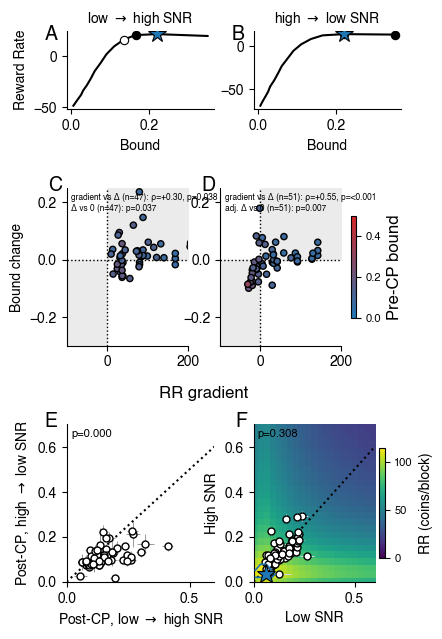

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure06.pdf (+ .png)


In [8]:
# ── Publication layout matching MATLAB getPLOT_axes(6, 8.5, [2,4,4], {2,2,2}, 2.0, 1.0) ──
CM       = 1 / 2.54
WID      = 8.5
HTS      = [2.0, 4.0, 4.0]
PSH      = 2.0
PSW      = 1.0
FS       = 12
HEADER_H = 0.6   # cm reserved above Row 1 for the column headers
GRAD_XLIM = (-100, 200)   # shared by both Row 2 panels
YLIM     = (-0.30, 0.25)
PRE_VMIN, PRE_VMAX = 0.0, 0.5

fig_h    = sum(HTS) + PSH * (len(HTS) - 1) + HEADER_H   # 2+4+4 + 2*2 + 0.6 = 14.6 cm
panel_w  = (WID - PSW) / 2                                # 3.75 cm
grid_top = 1 - HEADER_H / fig_h

fig_fmt = plt.figure(figsize=(WID * CM, fig_h * CM))
gs = gridspec.GridSpec(
    3, 2, figure=fig_fmt,
    height_ratios=HTS,
    hspace=PSH / np.mean(HTS),
    wspace=PSW / panel_w,
    left=0, right=1, bottom=0, top=grid_top,
)
axs_fmt = np.array([[fig_fmt.add_subplot(gs[r, c]) for c in range(2)] for r in range(3)])
plt.rcParams.update({'font.size': FS, 'axes.labelsize': FS, 'axes.titlesize': FS, **FONT_RC})

# ── Column headers ────────────────────────────────────────────────────────────
fig_fmt.canvas.draw()
header_y = grid_top + (1 - grid_top) / 2
col_titles = [r'low $\rightarrow$ high SNR', r'high $\rightarrow$ low SNR']
for tt in range(2):
    x_c = np.mean([axs_fmt[0, tt].get_position().x0, axs_fmt[0, tt].get_position().x1])
    fig_fmt.text(x_c, header_y, col_titles[tt], ha='center', va='center', fontsize=10)

# ── Row 1: example subject RR curve ──────────────────────────────────────────
# pre-CP bound = open (white) circle, post-CP bound = filled black circle — shape
# (not color) distinguishes the two, since Row 1 doesn't encode a continuous
# quantity the way Rows 2 and 3 do. Optimal bound stays a blue star throughout.
for tt in range(2):
    xs  = lh_bounds[:, 0] if tt == 0 else hl_bounds[:, 0]
    ys  = lh_bounds[:, 1] if tt == 0 else hl_bounds[:, 1]
    cpt = cp_lh             if tt == 0 else cp_hl
    pp  = EXAMPLE_SUBJECTS[tt]

    prei       = int(np.clip(np.searchsorted(BOUNDS, xs[pp], 'right') - 1, 0, len(BOUNDS) - 1))
    posti      = int(np.clip(np.searchsorted(BOUNDS, ys[pp], 'right') - 1, 0, len(BOUNDS) - 1))
    cp_idx_arr = np.where(cp_steps_by_cond[tt] == cpt[pp])[0]
    cp_idx     = int(cp_idx_arr[0]) if len(cp_idx_arr) else 0

    rrs    = pmats[tt][prei, :, cp_idx]
    kernel = np.ones(3) / 3
    rrs_sm = np.convolve(rrs, kernel, mode='same')
    rrs_sm[[0, -1]] = rrs[[0, -1]]
    maxi_sm = int(np.nanargmax(rrs_sm))  # smoothed argmax for display marker

    ax1 = axs_fmt[0, tt]
    ax1.plot(BOUNDS, rrs_sm, 'k-')
    ax1.plot(BOUNDS[prei],    rrs_sm[prei],    'o', markerfacecolor='white',
             markersize=6, markeredgecolor='k', markeredgewidth=0.8)
    ax1.plot(BOUNDS[maxi_sm], rrs_sm[maxi_sm], '*', color='tab:blue',
             markersize=13, markeredgecolor='k', markeredgewidth=0.8)
    ax1.plot(BOUNDS[posti],   rrs_sm[posti],   'o', markerfacecolor='black',
             markersize=6, markeredgecolor='k', markeredgewidth=0.8)
    ax1.set_xlabel('Bound')
    if tt == 0:
        ax1.set_ylabel('Reward Rate')
    add_panel_label(ax1, chr(65 + tt))

# ── Row 2: bound change vs. RR gradient ──────────────────────────────────────
# Fill color = pre-CP bound on a dedicated blue-red gradient (PRE_BOUND_CMAP,
# distinct from Row 3 panel F's viridis RR heatmap). Points use a single,
# uniform edge color (not split or colored by gradient direction). Each panel
# is annotated with the pooled Spearman correlation (gradient vs. Δ) and a
# Wilcoxon test of whether the bound change differs from zero (panel D uses
# the RR-gradient-adjusted Δ; see the stats cell above for why).
def _p(p):
    if not np.isfinite(p):
        return "n/a"
    return f"{p:.3f}" if p >= 0.001 else "<0.001"

def _rho(rho):
    return f"{rho:+.2f}" if np.isfinite(rho) else "n/a"

for tt in range(2):
    d, grad, pre = all_deltas[tt], all_gradient[tt], all_pre[tt]
    fin = np.isfinite(d) & np.isfinite(grad) & np.isfinite(pre) & (grad != 0)
    d, grad, pre = d[fin], grad[fin], pre[fin]

    ax2 = axs_fmt[1, tt]
    ax2.fill_between([GRAD_XLIM[0], 0], YLIM[0], 0, color='0.92', zorder=0)
    ax2.fill_between([0, GRAD_XLIM[1]], 0, YLIM[1], color='0.92', zorder=0)
    ax2.axhline(0, color='k', linestyle=':', linewidth=1, zorder=1)
    ax2.axvline(0, color='k', linestyle=':', linewidth=1, zorder=1)

    sc = ax2.scatter(grad, d, c=pre, cmap=PRE_BOUND_CMAP,
                      vmin=PRE_VMIN, vmax=PRE_VMAX, edgecolors='black',
                      linewidths=1.0, s=20, zorder=2)

    sa = spearman_pooled[TITLES[tt]]
    wm = wilcoxon_median[TITLES[tt]]
    delta_label = 'Δ' if tt == 0 else 'adj. Δ'

    annot = (f"gradient vs Δ (n={sa['n']}): ρ={_rho(sa['rho'])}, p={_p(sa['p'])}\n"
             f"{delta_label} vs 0 (n={wm['n']}): p={_p(wm['p'])}")
    ax2.text(0.04, 0.97, annot, transform=ax2.transAxes, ha='left', va='top',
             fontsize=FS - 6, linespacing=1.3)

    ax2.set_xlim(GRAD_XLIM)
    ax2.set_ylim(YLIM)
    add_panel_label(ax2, chr(67 + tt))

ax_row2_bottom = min(axs_fmt[1, 0].get_position().y0, axs_fmt[1, 1].get_position().y0)
axs_fmt[1, 0].set_ylabel('Bound change')
cbar = fig_fmt.colorbar(sc, ax=list(axs_fmt[1, :]), shrink=0.65, pad=0.03)
cbar.set_label('Pre-CP bound', fontsize=FS)
cbar.ax.tick_params(labelsize=FS - 4)

fig_fmt.canvas.draw()
x_c = np.mean([axs_fmt[1, 0].get_position().x0, axs_fmt[1, 1].get_position().x1])
fig_fmt.text(x_c, ax_row2_bottom - 0.07, 'RR gradient', ha='center',
             va='top', fontsize=FS)

# ── Row 3, panel E: post-CP bound comparison (LowHigh vs. HighLow) ──────────
# Errorbars = per-subject SEM (x: LowHigh post-CP, y: HighLow post-CP).
ax3 = axs_fmt[2, 0]
xs, ys = lh_bounds[:, 1], hl_bounds[:, 1]
xerr, yerr = sem_lh[:, 1], sem_hl[:, 1]
Lg = np.isfinite(xs) & np.isfinite(ys)
ax3.plot([0, 0.8], [0, 0.8], 'k:')
ax3.errorbar(xs[Lg], ys[Lg], xerr=xerr[Lg], yerr=yerr[Lg], fmt='o',
             markerfacecolor='white', markeredgecolor='k', markersize=5,
             ecolor='0.6', elinewidth=0.7, capsize=0, zorder=2)
_, p_e = scipy.stats.wilcoxon(xs[Lg], ys[Lg])
ax3.text(0.03, 0.97, f'p={p_e:.3f}', transform=ax3.transAxes, ha='left', va='top',
          fontsize=FS - 4)
add_panel_label(ax3, 'E')
ax3.set_xlabel(r'Post-CP, low $\rightarrow$ high SNR')
ax3.set_ylabel(r'Post-CP, high $\rightarrow$ low SNR')
ax3.set_xlim(0, 0.6)
ax3.set_ylim(0, 0.7)

# ── Row 3, panel F: Low vs. High stable-SNR bounds, over the RR landscape ───
# (stable_rr_matrix, computed above on the dedicated STABLE_BOUNDS grid so the
# heatmap fills the whole panel rather than just the CP-task BOUNDS range).
# Near-optimal (>=95% of max RR) region outlined with a thin blue contour and
# the peak marked with a blue star, matching Figure05_mixedVsBlockedSNR.ipynb's
# heatmap styling and this notebook's own Row 1 convention. Errorbars = per-
# subject SEM (x: Low stable bound, y: High stable bound).
ax4 = axs_fmt[2, 1]
xs, ys = lo_bounds[:, 0], hi_bounds[:, 0]
xerr, yerr = sem_lo[:, 0], sem_hi[:, 0]
Lg = np.isfinite(xs) & np.isfinite(ys)

b_min, b_max = STABLE_BOUNDS[0], STABLE_BOUNDS[-1]
half_step = (STABLE_BOUNDS[1] - STABLE_BOUNDS[0]) / 2
im = ax4.imshow(stable_rr_matrix, origin='lower',
                 extent=[b_min - half_step, b_max + half_step, b_min - half_step, b_max + half_step],
                 aspect='auto', vmin=0, vmax=stable_rr_matrix.max(), cmap='viridis', zorder=0)
ax4.plot([0, 0.8], [0, 0.8], 'k:', zorder=1)
ax4.errorbar(xs[Lg], ys[Lg], xerr=xerr[Lg], yerr=yerr[Lg], fmt='o',
             markerfacecolor='white', markeredgecolor='k', markersize=5,
             ecolor='0.85', elinewidth=0.7, capsize=0, zorder=2)

# Contour and peak marker are drawn last (above the participant scatter) so they
# stay visible even where the RR optimum coincides with where subjects cluster
# (as it does here) — matching Figure05_mixedVsBlockedSNR.ipynb's draw order.
near_opt = stable_rr_matrix >= 0.95 * stable_rr_matrix.max()
lo_grid, hi_grid = np.meshgrid(STABLE_BOUNDS, STABLE_BOUNDS)
ax4.contour(lo_grid, hi_grid, near_opt.astype(float), levels=[0.5],
            colors='tab:blue', linewidths=1.2, zorder=3)

ax4.plot(STABLE_BOUNDS[opt_lo_idx], STABLE_BOUNDS[opt_hi_idx], '*', color='tab:blue',
         markersize=14, markeredgecolor='k', markeredgewidth=0.8, zorder=4)

_, p_f = scipy.stats.wilcoxon(xs[Lg], ys[Lg])
ax4.text(0.03, 0.97, f'p={p_f:.3f}', transform=ax4.transAxes, ha='left', va='top',
          fontsize=FS - 4)
add_panel_label(ax4, 'F')
ax4.set_xlabel('Low SNR')
ax4.set_ylabel('High SNR')
ax4.set_xlim(0, 0.6)
ax4.set_ylim(0, 0.7)

cbar_f = fig_fmt.colorbar(im, ax=ax4, shrink=0.7, pad=0.03)
cbar_f.set_label('RR (coins/block)', fontsize=FS - 2)
cbar_f.ax.tick_params(labelsize=FS - 4)

for ax in axs_fmt.flat:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

out = FIGURES_DIR / 'Figure06.pdf'
fig_fmt.savefig(out, dpi=300, bbox_inches='tight')
fig_fmt.savefig(out.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out} (+ .png)')